1. average, median, and mode of PurchaseAmount

In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


dataSet = pd.read_csv("customer_behavior.csv")
print (dataSet.head())


average = dataSet['PurchaseAmount'].mean()
print("Average of Purchase Amount is : ",average)

dataSet["PurchaseAmount"] = dataSet["PurchaseAmount"].fillna(
    dataSet["PurchaseAmount"].mean()
)

median = dataSet['PurchaseAmount'].median()
print("Median of Purchase Amount is : ",median)

mode = dataSet['PurchaseAmount'].mode()
print("Mode of Purchase Amount is : ",mode)

print(dataSet.isnull().sum())

   CustomerID  Gender Region  PurchaseAmount ProductCategory Churn  \
0        1001    Male  South          256.07         Fashion    No   
1        1002  Female  South             NaN     Electronics   Yes   
2        1003  Female   West         1194.41         Fashion    No   
3        1004  Female  South          413.06         Grocery    No   
4        1005    Male   West         1556.32         Fashion   Yes   

  CampaignGroup  
0             A  
1             B  
2             A  
3             A  
4             A  
Average of Purchase Amount is :  1003.9506701030928
Median of Purchase Amount is :  1003.9506701030928
Mode of Purchase Amount is :  0    1003.95067
Name: PurchaseAmount, dtype: float64
CustomerID           0
Gender              97
Region             175
PurchaseAmount       0
ProductCategory    526
Churn              265
CampaignGroup      185
dtype: int64


2. To check any outliers in the PurchaseAmount data

IQR: 629.76
Q3: 1316.155
Q1: 686.395
Number of Outliers: 24
195     2318.33
265     2496.41
348     2688.69
411     2349.16
442     2291.79
702     2292.99
826     2578.89
1358    2384.19
1792    2265.18
2285    2457.05
2455    2286.38
2557    2316.19
2681    2400.69
3326    2357.41
3438    2688.88
3564    2643.88
3697    2261.69
3711    2301.24
4005    2290.15
4088    2273.03
4270    2262.25
4345    2472.62
4693    2484.75
4808    2642.06
Name: PurchaseAmount, dtype: float64


<Axes: ylabel='PurchaseAmount'>

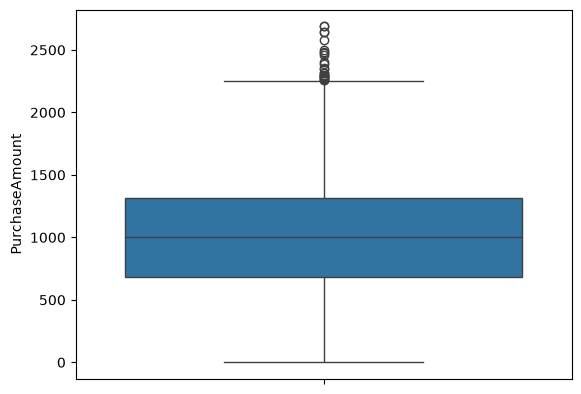

In [71]:
Q1 = dataSet["PurchaseAmount"].quantile(0.25)
Q3 = dataSet["PurchaseAmount"].quantile(0.75)

IQR = Q3 - Q1

print("IQR:",IQR)
print("Q3:",Q3)
print("Q1:",Q1)

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = dataSet[
    (dataSet["PurchaseAmount"] < lower) |
    (dataSet["PurchaseAmount"] > upper)
]

print("Number of Outliers:", len(outliers))
print(outliers["PurchaseAmount"])


sns.boxplot(dataSet["PurchaseAmount"])

There are 24 outliers.

3. To check any skewness or kurtosis in the PurchaseAmount distribution.

The Skewness is : 0.10768667914138372
The Kurtosis is : -0.1778122600130425


<Axes: xlabel='PurchaseAmount', ylabel='Count'>

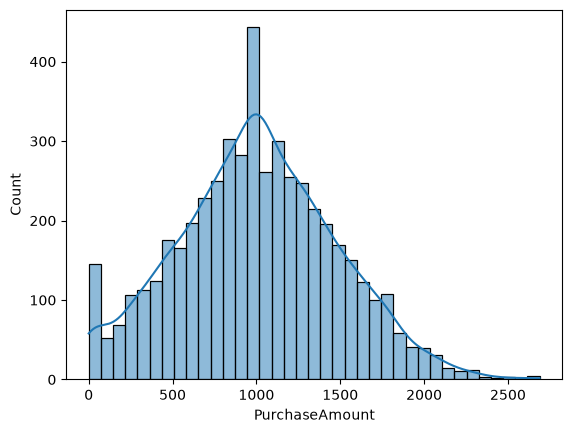

In [26]:
from scipy.stats import skew

skew_value = skew(dataSet["PurchaseAmount"])
print ("The Skewness is :",skew_value)

from scipy.stats import kurtosis

kurtosis_value = kurtosis(dataSet["PurchaseAmount"])

print("The Kurtosis is :",kurtosis_value)



The skewness value of 0.107 indicates that the PurchaseAmount distribution is approximately symmetric, with a very slight positive skew.
The kurtosis is slightly negative and distribution has slightly lighter tails which means it is Platykurtic.

4. To check a significant difference in spending between male and female customers

In [66]:
from scipy import stats

male = dataSet[dataSet["Gender"] == "Male"]["PurchaseAmount"].dropna()
female = dataSet[dataSet["Gender"] == "Female"]["PurchaseAmount"].dropna()

t_stat, p_value = stats.ttest_ind(male, female)

print("P-value:", p_value.round(2))

if p_value < 0.05:
    print("There is a significant difference in spending.")
else:
    print("There is no significant difference in spending.")

P-value: 0.03
There is a significant difference in spending.


There is a significant difference in spending between male and female customers.

5. To check relationship between ProductCategory and customer churn.

ProductCategory  Churn
Electronics      No       785
                 Yes      541
Fashion          No       839
                 Yes      607
Grocery          No       855
                 Yes      604
Name: count, dtype: int64


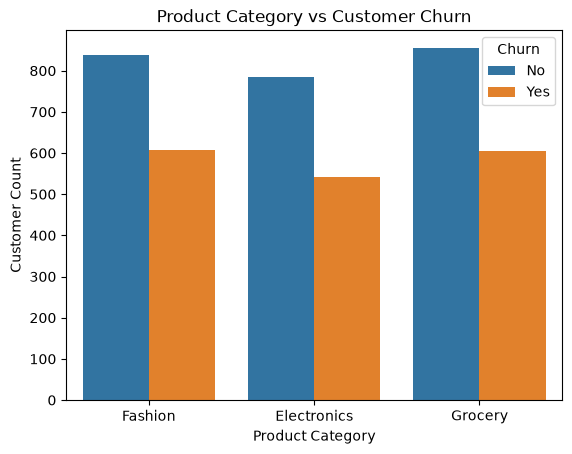

In [30]:
churn = dataSet.groupby("ProductCategory")["Churn"].value_counts()

print(churn)

sns.countplot(data=dataSet, x="ProductCategory", hue="Churn")

plt.title("Product Category vs Customer Churn")
plt.xlabel("Product Category")
plt.ylabel("Customer Count")
plt.show()

Fashion has the highest number of churned customers (607), followed by Grocery (604) and Electronics (541). Customer churn is observed across all three product categories.

6. To check PurchaseAmount vary significantly across different regions.

In [38]:
purchaseAmt_Region = dataSet.groupby("Region")["PurchaseAmount"].mean()

roundPurchase_region = purchaseAmt_Region.round(2)

region_show = pd.DataFrame({
    "Average Purchase Amount": roundPurchase_region
})

print(region_show)

        Average Purchase Amount
Region                         
East                    1009.79
North                   1012.69
South                    997.84
West                     995.44


PurchaseAmount varies slightly across different regions. North has the highest average spending, while West has the lowest.

7. To check which email campaign (A or B) performed better in terms of average PurchaseAmount

In [44]:
campaignGroup_Data = dataSet.groupby("CampaignGroup")["PurchaseAmount"].mean()

roundcampaignGroup_Data = campaignGroup_Data.round(2)

campaign_show = pd.DataFrame({
    "Average Purchase Amount": roundcampaignGroup_Data
})
print(campaign_show)

               Average Purchase Amount
CampaignGroup                         
A                              1011.66
B                               994.59


Campaign A customers spend slightly more on average than Campaign B customers. Therefore, Campaign A shows a higher average purchase amount.

8. Can we assume PurchaseAmount follows a normal distribution

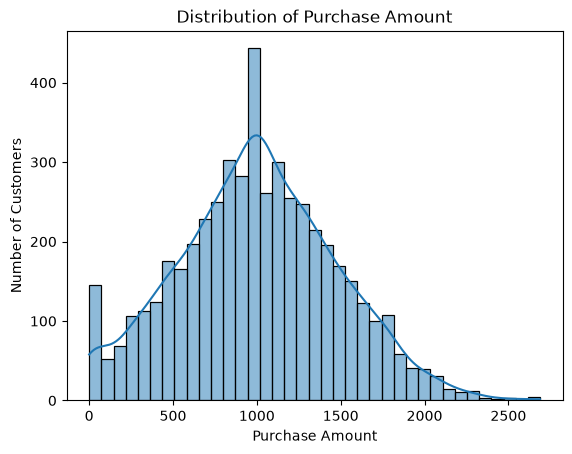

In [52]:
sns.histplot(dataSet["PurchaseAmount"], kde=True)

plt.title("Distribution of Purchase Amount")
plt.xlabel("Purchase Amount")
plt.ylabel("Number of Customers")
plt.show()

The PurchaseAmount distribution is approximately symmetric, with very little positive skewness. Its kurtosis is slightly negative, indicating a slightly flatter distribution than a normal distribution. Therefore, the data has some characteristics of a normal distribution but is not necessarily perfectly normally distributed.

9. Can we assume PurchaseAmount follows a normal distribution.

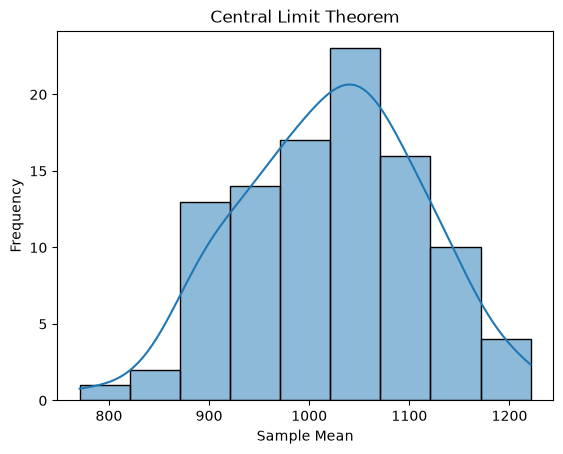

In [58]:
np.random.seed(42)

purchase = dataSet["PurchaseAmount"].dropna()

samples = purchase.sample(n=3000, replace=True)

sample_data = pd.DataFrame({
    "PurchaseAmount": samples.values,
    "Sample": np.repeat(range(1, 101), 30)
})

sample_means = sample_data.groupby("Sample")["PurchaseAmount"].mean()


sns.histplot(sample_means, kde=True)

plt.title("Central Limit Theorem")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.show()

According to the Central Limit Theorem, when we take a large number of random samples of size 30, the distribution of sample means becomes approximately normal. The sample means are close to the original average PurchaseAmount of 1003.95. This demonstrates the Central Limit Theorem.

10. What is the 95% confidence interval for the average PurchaseAmount.

In [63]:
purchase = dataSet["PurchaseAmount"].dropna()

mean = purchase.mean()
roundMean = mean.round(2)
std = purchase.std()
roundStd = std.round(2)
n = len(purchase)

lower = roundMean - (1.96 * roundStd / np.sqrt(n))
roundLower = lower.round(2)

upper = roundMean + (1.96 * roundStd / np.sqrt(n))
roundUpper = upper.round(2)

print("Mean:", roundMean)
print("95% Confidence Interval:", roundLower, "to", roundUpper)

Mean: 1003.95
95% Confidence Interval: 990.79 to 1017.11


The 95% confidence interval for the average purchase amount is approximately 990.38 to 1017.52. This means we are 95% confident that the actual population average purchase amount lies within this range.